In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create the data directory
Path("data").mkdir(exist_ok=True)

# Download the official UCI Heart Disease dataset
heart = fetch_ucirepo(id=45)

X = heart.data.features.copy()
y = heart.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

display(X.head())
display(y.head())

Features shape: (303, 13)
Target shape: (303, 1)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0


In [3]:
# Combine features and target for inspection
df = pd.concat([X, y], axis=1)

print("Dataset dimensions:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nUnique values in target:")
print(y.iloc[:, 0].value_counts(dropna=False).sort_index())

print("\nDuplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)

Dataset dimensions: (303, 14)

Column data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Unique values in target:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


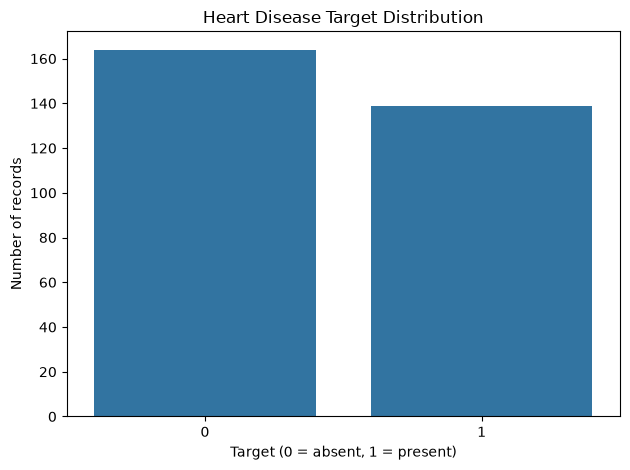

In [4]:
# Convert the diagnosis into binary classification:
# 0 = no heart disease
# 1 = heart disease present
target_col = y.columns[0]

df["target"] = (
    pd.to_numeric(df[target_col], errors="coerce") > 0
).astype(int)

# Remove the original target column
if target_col != "target":
    df = df.drop(columns=[target_col])

print("Binary target distribution:")
print(df["target"].value_counts())

sns.countplot(data=df, x="target")
plt.title("Heart Disease Target Distribution")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

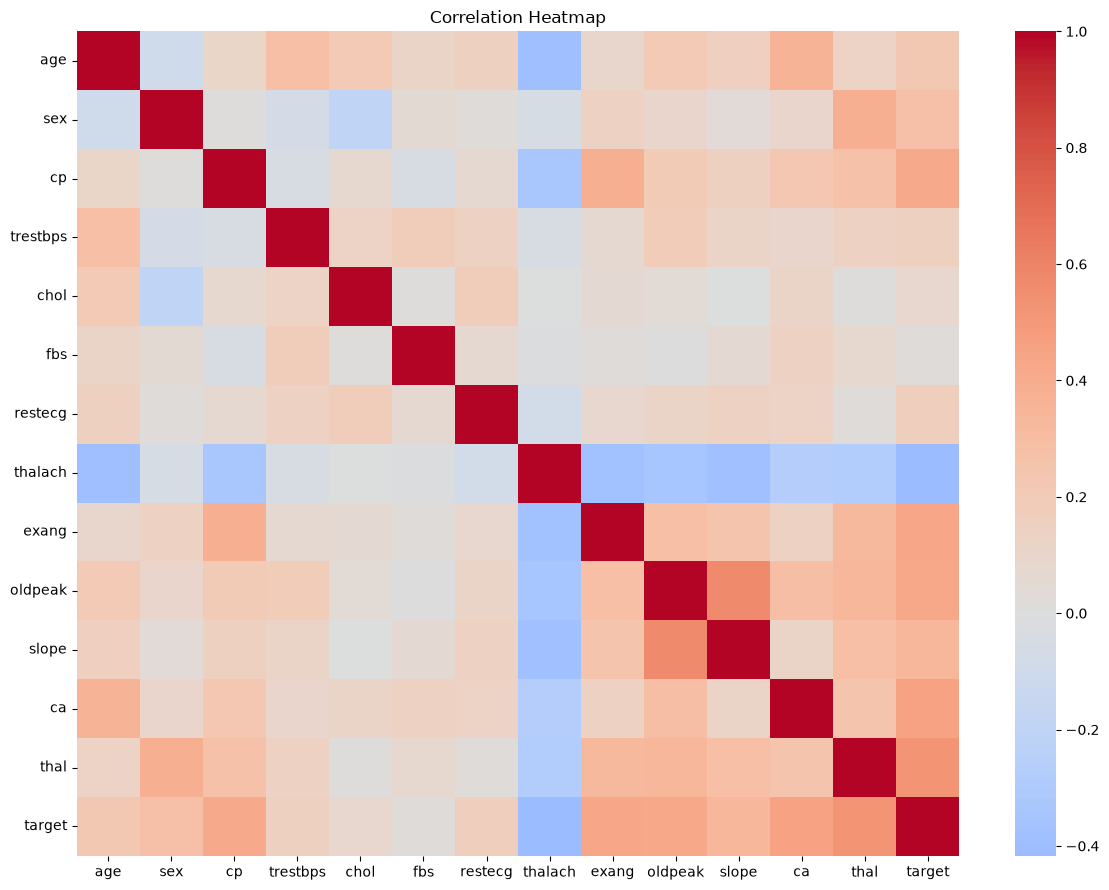

In [5]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 9))
sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [6]:
# Convert missing-value markers such as "?" to NaN
feature_cols = X.columns.tolist()

clean_df = df.copy()

for col in feature_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col], errors="coerce"
    )

# Drop rows with missing target, if any
clean_df = clean_df.dropna(subset=["target"])

clean_df.to_csv("data/heart_disease.csv", index=False)

print("Saved data/heart_disease.csv")
print("Final dimensions:", clean_df.shape)
print("Missing values per column:")
print(clean_df.isna().sum())

Saved data/heart_disease.csv
Final dimensions: (303, 14)
Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [7]:
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())

X exists: True
y exists: True


In [8]:
from pathlib import Path
import pandas as pd

# Check that the dataset variables exist
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())

# Rebuild the dataframe from the downloaded dataset
df = pd.concat([X, y], axis=1)

# Identify the original target column
target_col = y.columns[0]

# Convert the target to binary classification
df["target"] = (
    pd.to_numeric(df[target_col], errors="coerce") > 0
).astype(int)

# Remove the original target column
if target_col != "target":
    df = df.drop(columns=[target_col])

# Convert feature columns to numeric values
for col in X.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without a valid target
df = df.dropna(subset=["target"])

# Save relative to the repository root
output_dir = Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "heart_disease.csv"
df.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("Dataset shape:", df.shape)
print("File exists:", output_path.exists())

X exists: True
y exists: True
Saved to: /workspaces/mlops-heart-disease/notebooks/data/heart_disease.csv
Dataset shape: (303, 14)
File exists: True


In [9]:
from ucimlrepo import fetch_ucirepo

heart = fetch_ucirepo(id=45)
X = heart.data.features.copy()
y = heart.data.targets.copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (303, 13)
Target: (303, 1)


In [10]:
from pathlib import Path
import pandas as pd

# Combine input features and original diagnosis
df = pd.concat([X, y], axis=1)

# Convert diagnosis into binary classification
target_col = y.columns[0]
df["target"] = (
    pd.to_numeric(df[target_col], errors="coerce") > 0
).astype(int)

# Remove the original diagnosis column
if target_col != "target":
    df = df.drop(columns=[target_col])

# Convert features to numeric; invalid values become missing
for col in X.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing targets
df = df.dropna(subset=["target"])

# Save the dataset
output_path = Path.cwd() / "data" / "heart_disease.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", df.shape)
print("File exists:", output_path.exists())

Saved to: /workspaces/mlops-heart-disease/notebooks/data/heart_disease.csv
Dataset shape: (303, 14)
File exists: True


In [11]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

output_path = DATA_DIR / "heart_disease.csv"
print(output_path)

/workspaces/mlops-heart-disease/data/heart_disease.csv
